In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("gorororororo23/laliga-team-logos-dataset-for-cnn")

print("Path to dataset files:", path)

100%|██████████| 29.9M/29.9M [00:02<00:00, 12.9MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/gorororororo23/laliga-team-logos-dataset-for-cnn/versions/1


In [3]:
from pathlib import Path

DATA_DIR = Path(
    "/root/.cache/kagglehub/datasets/"
    "gorororororo23/laliga-team-logos-dataset-for-cnn/"
    "versions/1"
)

print("Dataset exists:", DATA_DIR.exists())
print("\nFiles and folders inside Dataset:")

for item in sorted(DATA_DIR.iterdir()):
    print(item.name, "->", "Directory" if item.is_dir() else "File")

Dataset exists: True

Files and folders inside Dataset:
Laliga teams -> Directory


In [4]:
from pathlib import Path
from collections import Counter

IMAGE_DIR = DATA_DIR / "Laliga teams"

VALID_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

class_dirs = sorted(
    folder for folder in IMAGE_DIR.iterdir()
    if folder.is_dir()
)

print("Number of classes:", len(class_dirs))

total_images = 0
class_counts = {}

for folder in class_dirs:
    images = [
        file for file in folder.iterdir()
        if file.is_file()
        and file.suffix.lower() in VALID_EXTENSIONS
    ]

    class_counts[folder.name] = len(images)
    total_images += len(images)

    print(f"{folder.name}: {len(images)} images")

print("\nTotal images:", total_images)

print(
    "Classes with unexpected image count:",
    {
        name: count
        for name, count in class_counts.items()
        if count != 100
    }
)

Number of classes: 20
Athletic Bilbao: 100 images
Atletico Madrid: 100 images
Barcelona: 100 images
Celta Vigo: 100 images
Deportivo Alaves: 100 images
Espanyol: 100 images
Getafe: 100 images
Girona: 100 images
Las Palmas: 100 images
Leganes: 100 images
Mallorca: 100 images
Osasuna: 100 images
Rayo Vallecano: 100 images
Real Betis: 100 images
Real Madrid: 100 images
Real Sociedad: 100 images
Real Valladolid: 100 images
Sevilla: 100 images
Valencia: 100 images
Villarreal: 100 images

Total images: 2000
Classes with unexpected image count: {}


In [5]:
from PIL import Image, UnidentifiedImageError
from collections import defaultdict
import hashlib

all_images = sorted(
    path
    for class_dir in class_dirs
    for path in class_dir.iterdir()
    if path.is_file()
    and path.suffix.lower() in VALID_EXTENSIONS
)

corrupted_images = []
image_modes = Counter()
image_sizes = Counter()
hash_to_paths = defaultdict(list)

for path in all_images:
    try:
        with Image.open(path) as img:
            img.verify()

        with Image.open(path) as img:
            image_modes[img.mode] += 1
            image_sizes[img.size] += 1

        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        hash_to_paths[digest].append(path)

    except (OSError, ValueError, UnidentifiedImageError) as error:
        corrupted_images.append((path, str(error)))

duplicate_groups = [
    paths for paths in hash_to_paths.values()
    if len(paths) > 1
]

duplicate_extras = sum(
    len(paths) - 1 for paths in duplicate_groups
)

print("Total scanned:", len(all_images))
print("Corrupted images:", len(corrupted_images))
print("Image modes:", image_modes)
print("\nMost common image sizes:")
print(image_sizes.most_common(10))

print("\nExact duplicate groups:", len(duplicate_groups))
print("Extra duplicate files:", duplicate_extras)

for paths in duplicate_groups[:10]:
    print("\nDuplicate group:")
    for path in paths:
        print(" ", path.relative_to(IMAGE_DIR))

if corrupted_images:
    print("\nCorrupted file details:")
    for path, error in corrupted_images:
        print(path, error)

Total scanned: 2000
Corrupted images: 0
Image modes: Counter({'RGB': 2000})

Most common image sizes:
[((225, 225), 200), ((194, 260), 200), ((211, 239), 100), ((198, 254), 100), ((223, 226), 100), ((169, 299), 100), ((225, 224), 100), ((188, 267), 100), ((220, 230), 100), ((171, 295), 100)]

Exact duplicate groups: 1
Extra duplicate files: 1

Duplicate group:
  Girona/img20.jpg
  Girona/img48.jpg


Original images: 2000
Unique images: 1999
Removed from working list: 1


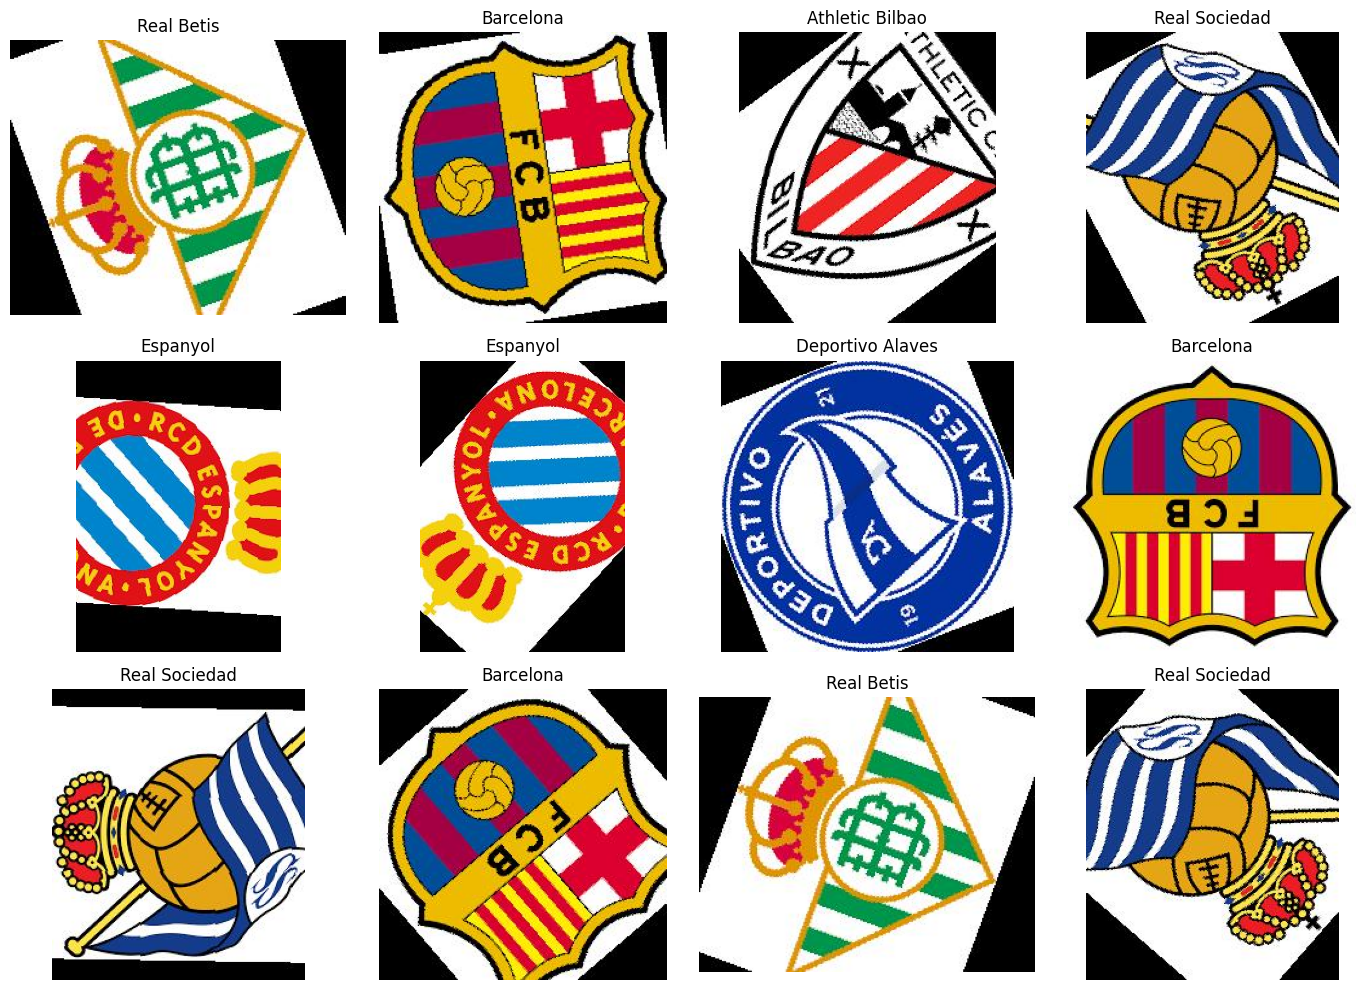

In [6]:
import random
import matplotlib.pyplot as plt
from PIL import Image

duplicate_paths = {
    str(path)
    for paths in duplicate_groups
    for path in paths[1:]
}

unique_images = [
    path for path in all_images
    if str(path) not in duplicate_paths
]

print("Original images:", len(all_images))
print("Unique images:", len(unique_images))
print("Removed from working list:", len(all_images) - len(unique_images))

random.seed(42)
samples = random.sample(unique_images, 12)

plt.figure(figsize=(14, 10))

for i, path in enumerate(samples):
    with Image.open(path) as img:
        image = img.convert("RGB").copy()

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(path.parent.name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.DataFrame({
    "filepath": [str(path) for path in unique_images],
    "label": [path.parent.name for path in unique_images]
})

class_names = sorted(df["label"].unique())

class_to_index = {
    name: index
    for index, name in enumerate(class_names)
}

print("Total images:", len(df))
print("Number of classes:", len(class_names))

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("\nTrain:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nClasses in each split:")
print("Train:", train_df["label"].nunique())
print("Validation:", val_df["label"].nunique())
print("Test:", test_df["label"].nunique())

train_paths = set(train_df["filepath"])
val_paths = set(val_df["filepath"])
test_paths = set(test_df["filepath"])

print("\nTrain-Val overlap:", len(train_paths & val_paths))
print("Train-Test overlap:", len(train_paths & test_paths))
print("Val-Test overlap:", len(val_paths & test_paths))

distribution = pd.DataFrame({
    "Train": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Test": test_df["label"].value_counts()
}).sort_index()

print("\nClass distribution:")
display(distribution)

Total images: 1999
Number of classes: 20

Train: 1399
Validation: 300
Test: 300

Classes in each split:
Train: 20
Validation: 20
Test: 20

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0

Class distribution:


,Train,Validation,Test
label,,,
Athletic Bilbao,70,15,15
Atletico Madrid,70,15,15
Barcelona,70,15,15
Celta Vigo,70,15,15
Deportivo Alaves,70,15,15
Espanyol,70,15,15
Getafe,70,15,15
Girona,69,15,15
Las Palmas,70,15,15


In [8]:
import tensorflow as tf
import numpy as np

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(filepath, label):
    image_bytes = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    # Resize to a fixed size
    image = tf.image.resize(image, IMG_SIZE)

    # Normalize pixels to [0, 1]
    image = tf.cast(image, tf.float32) / 255.0

    return image, label


def build_dataset(dataframe, training=False):
    paths = dataframe["filepath"].to_numpy()

    labels = dataframe["label"].map(
        class_to_index
    ).to_numpy(dtype=np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = build_dataset(train_df, training=True)
val_ds = build_dataset(val_df)
test_ds = build_dataset(test_df)

print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Train batches: 44
Validation batches: 10
Test batches: 10


In [9]:
import matplotlib.pyplot as plt
import tensorflow as tf

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(
        factor=0.04,
        fill_mode="nearest",
        seed=42
    ),

    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05,
        fill_mode="nearest",
        seed=43
    ),

    tf.keras.layers.RandomZoom(
        height_factor=0.08,
        width_factor=0.08,
        fill_mode="nearest",
        seed=44
    ),

    tf.keras.layers.RandomContrast(
        factor=0.10,
        seed=45
    )
], name="data_augmentation")

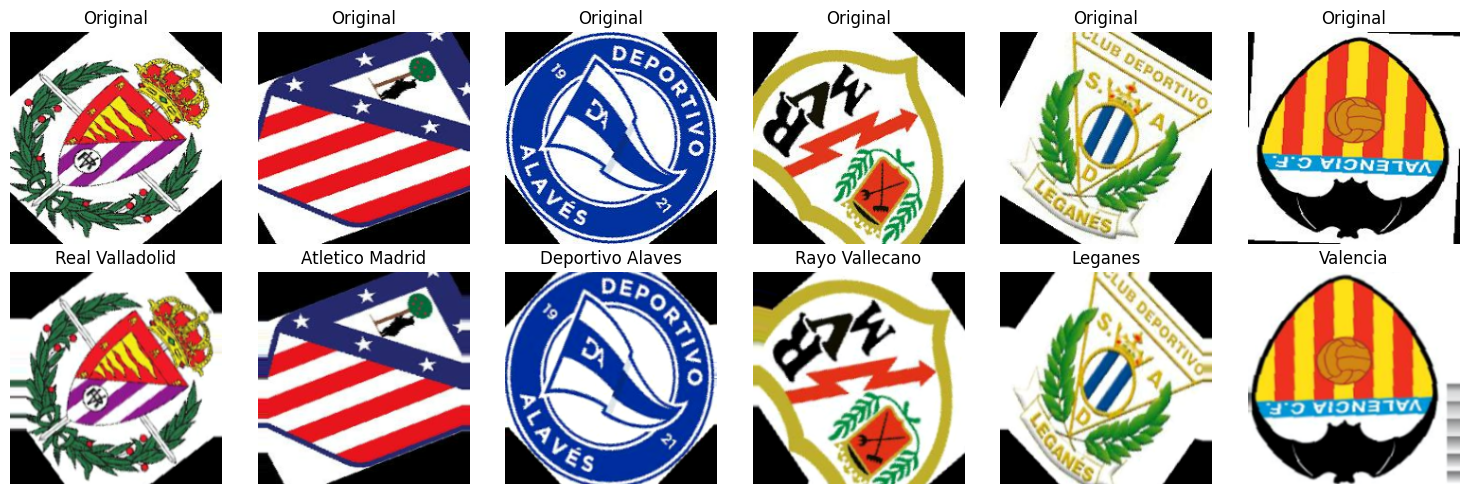

In [10]:
images, labels = next(iter(train_ds))

sample_images = images[:6]
sample_labels = labels[:6]

augmented_images = data_augmentation(
    sample_images,
    training=True
)

plt.figure(figsize=(15, 5))

for i in range(6):
    # Original image
    plt.subplot(2, 6, i + 1)
    plt.imshow(sample_images[i].numpy())
    plt.title("Original")
    plt.axis("off")

    # Augmented image
    plt.subplot(2, 6, i + 7)
    plt.imshow(
        tf.clip_by_value(
            augmented_images[i], 0.0, 1.0
        ).numpy()
    )
    plt.title(class_names[int(sample_labels[i])])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    layers.Conv2D(
        32, kernel_size=3,
        padding="same", activation="relu"
    ),
    layers.MaxPooling2D(),

    layers.Conv2D(
        64, kernel_size=3,
        padding="same", activation="relu"
    ),
    layers.MaxPooling2D(),

    layers.Conv2D(
        128, kernel_size=3,
        padding="same", activation="relu"
    ),
    layers.MaxPooling2D(),


    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(20, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 112,340 (438.83 KB)

 Trainable params: 112,340 (438.83 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    ModelCheckpoint(
        "best_laliga_cnn.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.0746 - loss: 2.9657
Epoch 1: val_loss improved from None to 2.42876, saving model to best_laliga_cnn.keras

Epoch 1: finished saving model to best_laliga_cnn.keras
44/44 ━━━━━━━━━━━━━━━━━━━━ 218s 5s/step - accuracy: 0.1058 - loss: 2.8773 - val_accuracy: 0.2667 - val_loss: 2.4288 - learning_rate: 0.0010
Epoch 2/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.2245 - loss: 2.3611
Epoch 2: val_loss improved from 2.42876 to 1.38317, saving model to best_laliga_cnn.keras

Epoch 2: finished saving model to best_laliga_cnn.keras
44/44 ━━━━━━━━━━━━━━━━━━━━ 235s 4s/step - accuracy: 0.2888 - loss: 2.1516 - val_accuracy: 0.7200 - val_loss: 1.3832 - learning_rate: 0.0010
Epoch 3/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.4916 - loss: 1.4663
Epoch 3: val_loss improved from 1.38317 to 0.70341, saving model to best_laliga_cnn.keras

Epoch 3: finished saving model to best_laliga_cnn.keras
44/44 ━━━━━━━━━━━━━━━━━━━━ 193s 4

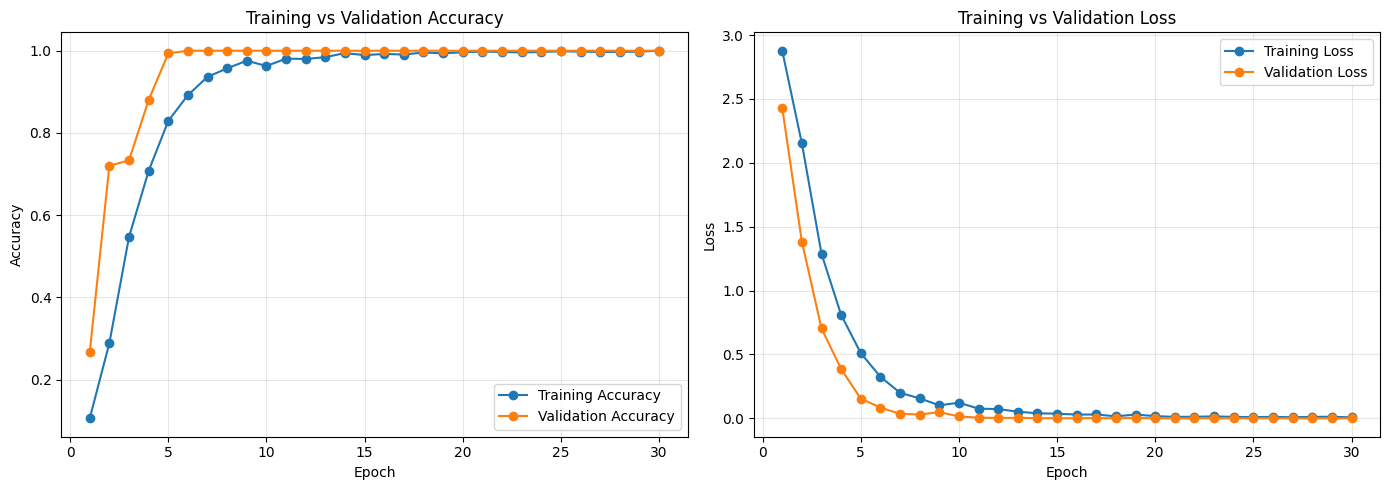

In [36]:
import matplotlib.pyplot as plt

# Extract training history
train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs = range(1, len(train_accuracy) + 1)

# Plot Accuracy and Loss
plt.figure(figsize=(14, 5))

# Accuracy Curve
plt.subplot(1, 2, 1)
plt.plot(epochs, train_accuracy, marker="o", label="Training Accuracy")
plt.plot(epochs, val_accuracy, marker="o", label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

# Loss Curve
plt.subplot(1, 2, 2)
plt.plot(epochs, train_loss, marker="o", label="Training Loss")
plt.plot(epochs, val_loss, marker="o", label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

10/10 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 1.0000 - loss: 1.2541e-04

Test Loss: 0.000125
Test Accuracy: 100.0000%
10/10 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step

Accuracy from predictions: 1.0

Classification Report:
                  precision    recall  f1-score   support

 Athletic Bilbao     1.0000    1.0000    1.0000        15
 Atletico Madrid     1.0000    1.0000    1.0000        15
       Barcelona     1.0000    1.0000    1.0000        15
      Celta Vigo     1.0000    1.0000    1.0000        15
Deportivo Alaves     1.0000    1.0000    1.0000        15
        Espanyol     1.0000    1.0000    1.0000        15
          Getafe     1.0000    1.0000    1.0000        15
          Girona     1.0000    1.0000    1.0000        15
      Las Palmas     1.0000    1.0000    1.0000        15
         Leganes     1.0000    1.0000    1.0000        15
        Mallorca     1.0000    1.0000    1.0000        15
         Osasuna     1.0000    1.0000    1.0000        15
  Rayo Vallecano     1.0000

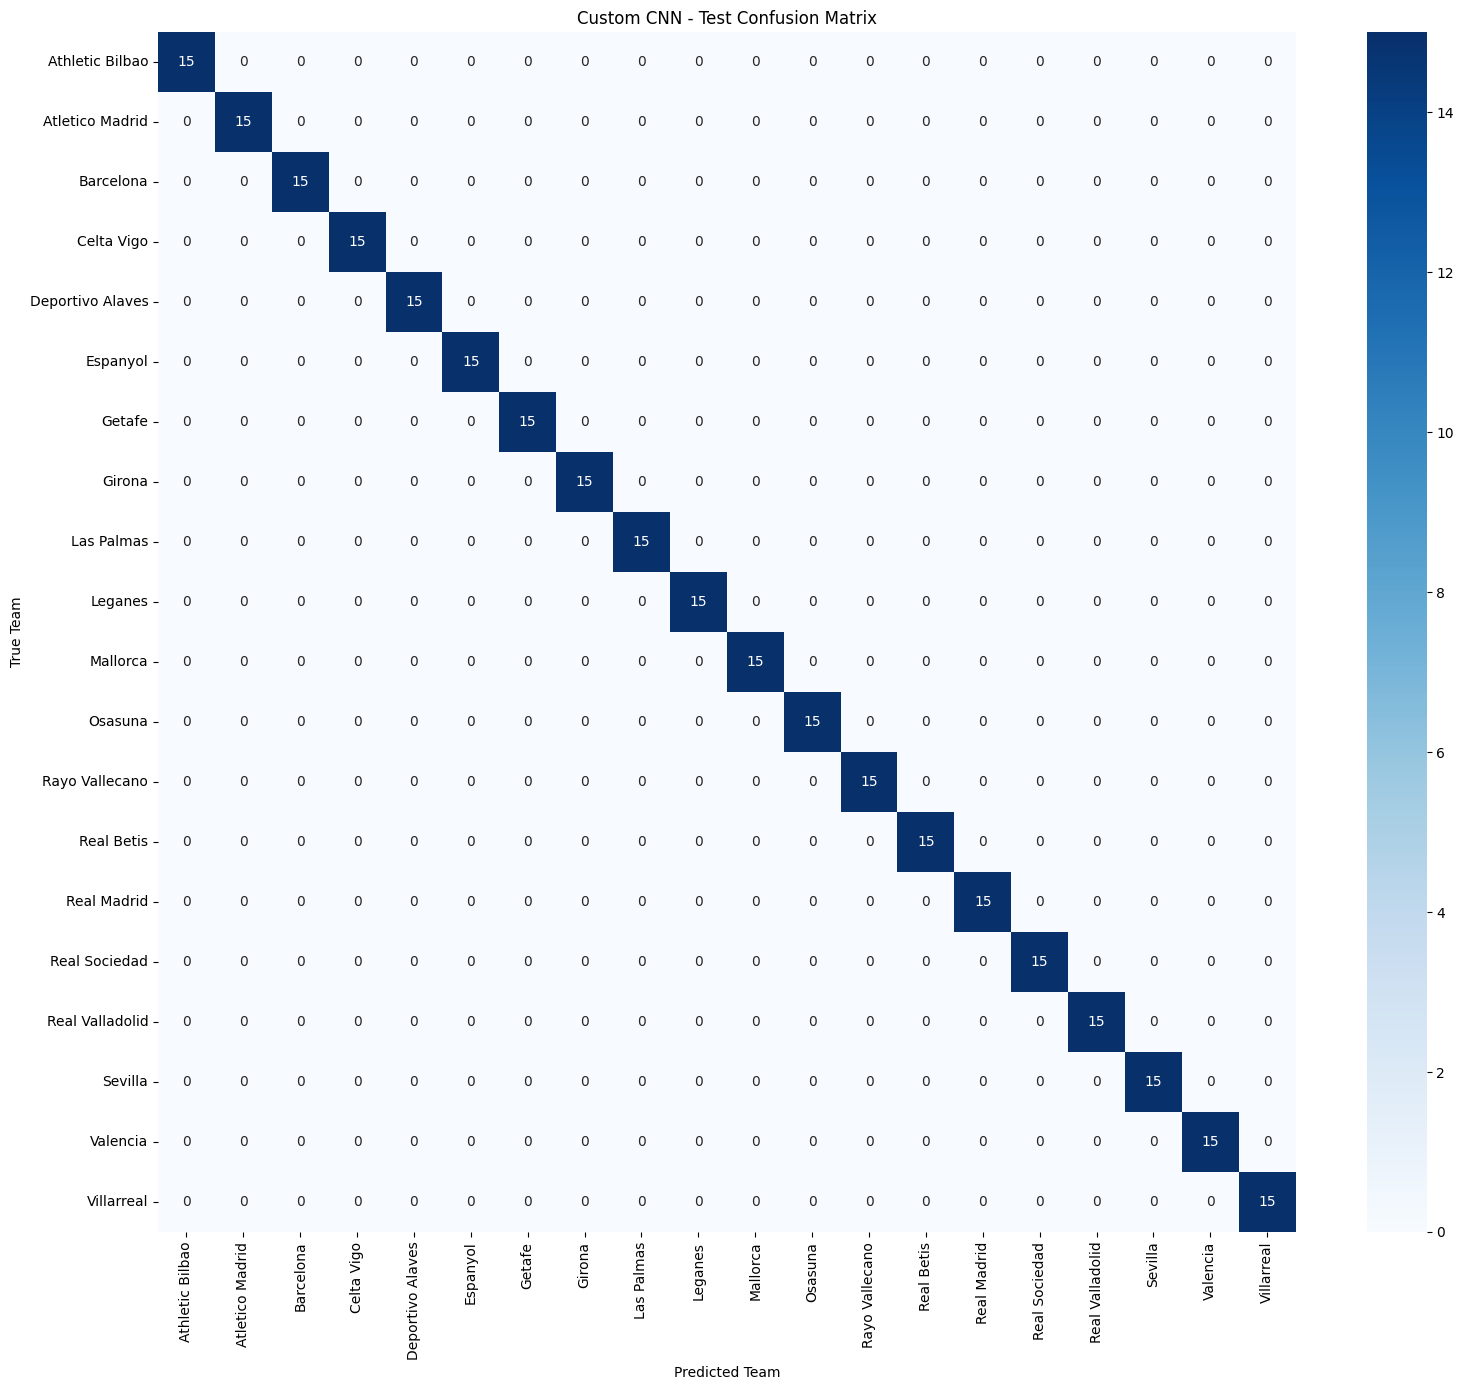

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Evaluate on the untouched test set
test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

print(f"\nTest Loss: {test_loss:.6f}")
print(f"Test Accuracy: {test_accuracy:.4%}")

# Get true labels and predictions
y_true = np.concatenate([
    labels.numpy()
    for _, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("\nAccuracy from predictions:", accuracy_score(y_true, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# Check prediction distribution
print("\nPredictions per class:")
for index, name in enumerate(class_names):
    count = int(np.sum(y_pred == index))
    print(f"{name}: {count}")

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

plt.figure(figsize=(16, 14))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Custom CNN - Test Confusion Matrix")
plt.xlabel("Predicted Team")
plt.ylabel("True Team")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [28]:
from google.colab import files

uploaded = files.upload()

Saving img12.jpg to img12.jpg


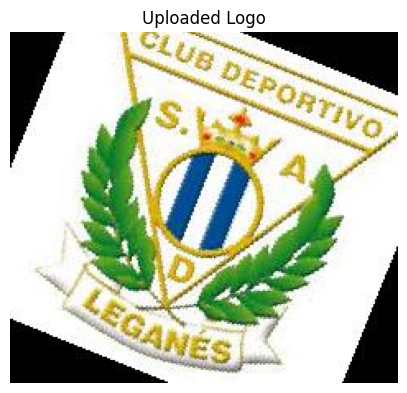

Predicted Team: Leganes
Confidence: 100.00%

Top 3 Predictions:
Leganes: 100.00%
Real Betis: 0.00%
Rayo Vallecano: 0.00%


In [29]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Get uploaded image path
image_path = next(iter(uploaded.keys()))

# Load and preprocess image
img = Image.open(image_path).convert("RGB")
display_img = img.copy()

img = img.resize((224, 224))
img_array = np.array(img, dtype=np.float32) / 255.0
img_array = np.expand_dims(img_array, axis=0)

# Predict
predictions = model.predict(img_array, verbose=0)[0]

predicted_index = np.argmax(predictions)
predicted_team = class_names[predicted_index]
confidence = predictions[predicted_index] * 100

# Display results
plt.figure(figsize=(5, 5))
plt.imshow(display_img)
plt.axis("off")
plt.title("Uploaded Logo")
plt.show()

print("Predicted Team:", predicted_team)
print(f"Confidence: {confidence:.2f}%")

# Show top 3 predictions
top_3 = np.argsort(predictions)[-3:][::-1]

print("\nTop 3 Predictions:")
for index in top_3:
    print(f"{class_names[index]}: {predictions[index] * 100:.2f}%")

In [30]:
from google.colab import files

uploaded = files.upload()

Saving img1.jpg to img1 (1).jpg


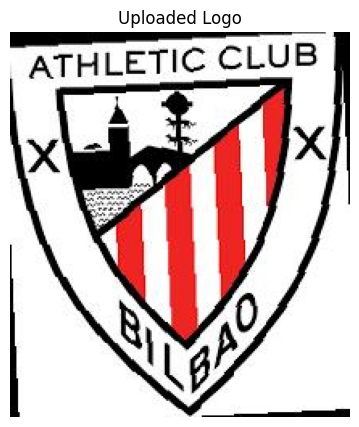

Predicted Team: Athletic Bilbao
Confidence: 100.00%

Top 3 Predictions:
Athletic Bilbao: 100.00%
Real Valladolid: 0.00%
Osasuna: 0.00%


In [31]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Get uploaded image path
image_path = next(iter(uploaded.keys()))

# Load and preprocess image
img = Image.open(image_path).convert("RGB")
display_img = img.copy()

img = img.resize((224, 224))
img_array = np.array(img, dtype=np.float32) / 255.0
img_array = np.expand_dims(img_array, axis=0)

# Predict
predictions = model.predict(img_array, verbose=0)[0]

predicted_index = np.argmax(predictions)
predicted_team = class_names[predicted_index]
confidence = predictions[predicted_index] * 100

# Display results
plt.figure(figsize=(5, 5))
plt.imshow(display_img)
plt.axis("off")
plt.title("Uploaded Logo")
plt.show()

print("Predicted Team:", predicted_team)
print(f"Confidence: {confidence:.2f}%")

# Show top 3 predictions
top_3 = np.argsort(predictions)[-3:][::-1]

print("\nTop 3 Predictions:")
for index in top_3:
    print(f"{class_names[index]}: {predictions[index] * 100:.2f}%")

In [32]:
from google.colab import files

uploaded = files.upload()

Saving img13.jpg to img13.jpg


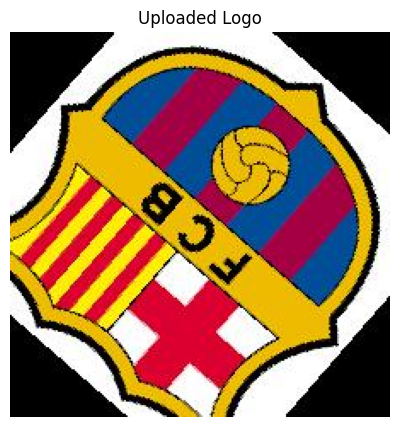

Predicted Team: Barcelona
Confidence: 99.98%

Top 3 Predictions:
Barcelona: 99.98%
Mallorca: 0.01%
Valencia: 0.00%


In [33]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Get uploaded image path
image_path = next(iter(uploaded.keys()))

# Load and preprocess image
img = Image.open(image_path).convert("RGB")
display_img = img.copy()

img = img.resize((224, 224))
img_array = np.array(img, dtype=np.float32) / 255.0
img_array = np.expand_dims(img_array, axis=0)

# Predict
predictions = model.predict(img_array, verbose=0)[0]

predicted_index = np.argmax(predictions)
predicted_team = class_names[predicted_index]
confidence = predictions[predicted_index] * 100

# Display results
plt.figure(figsize=(5, 5))
plt.imshow(display_img)
plt.axis("off")
plt.title("Uploaded Logo")
plt.show()

print("Predicted Team:", predicted_team)
print(f"Confidence: {confidence:.2f}%")

# Show top 3 predictions
top_3 = np.argsort(predictions)[-3:][::-1]

print("\nTop 3 Predictions:")
for index in top_3:
    print(f"{class_names[index]}: {predictions[index] * 100:.2f}%")

In [34]:
from google.colab import files

uploaded = files.upload()

Saving img18.jpg to img18.jpg


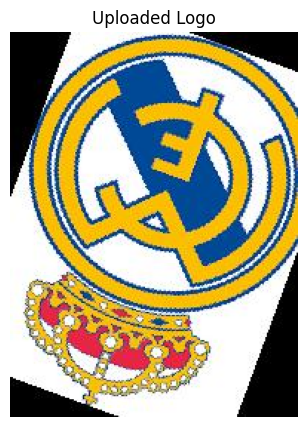

Predicted Team: Real Madrid
Confidence: 100.00%

Top 3 Predictions:
Real Madrid: 100.00%
Las Palmas: 0.00%
Real Sociedad: 0.00%


In [35]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Get uploaded image path
image_path = next(iter(uploaded.keys()))

# Load and preprocess image
img = Image.open(image_path).convert("RGB")
display_img = img.copy()

img = img.resize((224, 224))
img_array = np.array(img, dtype=np.float32) / 255.0
img_array = np.expand_dims(img_array, axis=0)

# Predict
predictions = model.predict(img_array, verbose=0)[0]

predicted_index = np.argmax(predictions)
predicted_team = class_names[predicted_index]
confidence = predictions[predicted_index] * 100

# Display results
plt.figure(figsize=(5, 5))
plt.imshow(display_img)
plt.axis("off")
plt.title("Uploaded Logo")
plt.show()

print("Predicted Team:", predicted_team)
print(f"Confidence: {confidence:.2f}%")

# Show top 3 predictions
top_3 = np.argsort(predictions)[-3:][::-1]

print("\nTop 3 Predictions:")
for index in top_3:
    print(f"{class_names[index]}: {predictions[index] * 100:.2f}%")

# LaLiga Team Logo Classification Using CNN

## 1. Project Overview

This project aims to build a Convolutional Neural Network (CNN) capable of classifying football club logos into 20 LaLiga team categories.

The project covers image preprocessing, exploratory data inspection, data augmentation, model development, training, evaluation, and prediction on external images.

## 2. Project Objectives

- Prepare and organize the image dataset.
- Build training, validation, and test sets.
- Apply data augmentation to improve model generalization.
- Develop and train a CNN for multiclass image classification.
- Evaluate the model using accuracy, loss, and classification metrics.
- Test the model on images obtained from outside the original dataset.

## 3. Dataset Description

The dataset was obtained from Kaggle: `gorororororo23/laliga-team-logos-dataset-for-cnn`.

The original dataset contains approximately 2,000 images representing 20 football teams. One exact duplicate image was removed before splitting.

| Dataset Split | Number of Images |
|---|---:|
| Training | 1,399 |
| Validation | 300 |
| Test | 300 |
| **Total** | **1,999** |

The data was split into training, validation, and test sets while maintaining approximately the same class distribution.

## 4. Image Preprocessing

The following preprocessing steps were applied:

- Converted images to RGB format.
- Resized images to 224 × 224 pixels.
- Normalized pixel values to the range [0, 1].
- Used batches of 32 images.
- Applied data augmentation during training.

The augmentation techniques included small rotations, translations, zoom transformations, and contrast adjustments. Horizontal flipping was excluded to preserve the original orientation of logo details.

## 5. CNN Architecture

The model consists of the following components:

1. Input layer: 224 × 224 × 3.
2. Data augmentation.
3. Convolutional layer with 32 filters and ReLU activation.
4. Max pooling.
5. Convolutional layer with 64 filters and ReLU activation.
6. Max pooling.
7. Convolutional layer with 128 filters and ReLU activation.
8. Max pooling.
9. Global Average Pooling.
10. Dense layer with 128 units and ReLU activation.
11. Dropout layer with a rate of 0.4.
12. Output layer with 20 units and Softmax activation.

## 6. Model Training

The model was trained using the following configuration:

- Optimizer: Adam.
- Initial learning rate: 0.001.
- Loss function: Sparse Categorical Crossentropy.
- Evaluation metric during training: Accuracy.
- Maximum epochs: 30.
- EarlyStopping to restore the best weights.
- ReduceLROnPlateau to reduce the learning rate when validation loss stops improving.
- ModelCheckpoint to save the best model according to validation loss.

## 7. Model Evaluation

The recorded test results were:

- Test Accuracy: 100%.
- Test Loss: 0.000125.

The classification report also showed perfect precision, recall, and F1-score on the 300-image test set.

These results describe performance on the current test split. They do not guarantee the same performance on unseen real-world images. Visually similar images may exist across different splits, so independent external testing is important.

## 8. External Image Prediction

An image from outside the original dataset can be uploaded to test whether the model correctly identifies its team.

The model returns the predicted team and its associated softmax score. This score represents the model's relative confidence among the 20 known classes and should not be interpreted as a guarantee that the prediction is correct.

## 9. Limitations and Future Improvements

- Test multiple external images from different sources.
- Evaluate logos with different backgrounds, resolutions, and designs.
- Investigate perceptually similar images across dataset splits.
- Create a more rigorous evaluation split by grouping near-duplicate images before splitting.
- Explore transfer learning with a pretrained CNN if external performance needs improvement.
- Develop a simple application for interactive logo classification.

## 10. Conclusion

This project demonstrates an end-to-end image classification workflow using TensorFlow and CNNs. The model achieved 100% test accuracy on the current test split. External testing and a more rigorous split based on image similarity are the next steps toward assessing its real-world generalization.